In [36]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23/DeepFakeDetection/01_02__meeting_serious__YVGY8LOK.mp4
/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23/DeepFakeDetection/01_02__outside_talking_still_laughing__YVGY8LOK.mp4
/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23/DeepFakeDetection/01_02__talking_against_wall__YVGY8LOK.mp4
/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23/DeepFakeDetection/01_02__walk_down_hall_angry__YVGY8LOK.mp4
/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23/DeepFakeDetection/01_02__walking_down_indoor_hall_disgust__YVGY8LOK.mp4
/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23/DeepFakeDetection/01_03__hugging_happy__ISF9SP4G.mp4
/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23/DeepFakeDetection/01_03__kitchen_pan__JZUXXFRB.mp4
/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23/DeepFakeDetection/01_03__podium_speech_happy__480LQD1C.mp4
/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C2

Using Device: cuda
Discovered -> Real Videos: 890, Fake Videos: 12639


Extracting Faces (Label 1):   4%|▍         | 499/12639 [00:50<20:21,  9.94it/s]


Extracted Total Face Frames: 1000 (Real: 500, Fake: 500)
Training on 800 frames, Validating on 200 frames.


Epoch 1/8 [Train]: 100%|██████████| 50/50 [00:07<00:00,  6.79it/s]


Epoch [1/8] Training Loss: 0.6801


Epoch 2/8 [Train]: 100%|██████████| 50/50 [00:07<00:00,  6.74it/s]


... (11 outputs left out)

Epoch 8/8 [Train]: 100%|██████████| 50/50 [00:07<00:00,  6.36it/s]


Epoch [8/8] Training Loss: 0.2940


Evaluating: 100%|██████████| 13/13 [00:00<00:00, 13.74it/s]



       EVALUATION METRICS       
Accuracy:  85.00%
Precision: 0.9070
Recall:    0.7800
F1-Score:  0.8387
ROC-AUC:   0.9132

Confusion Matrix:
[[92  8]
 [22 78]]


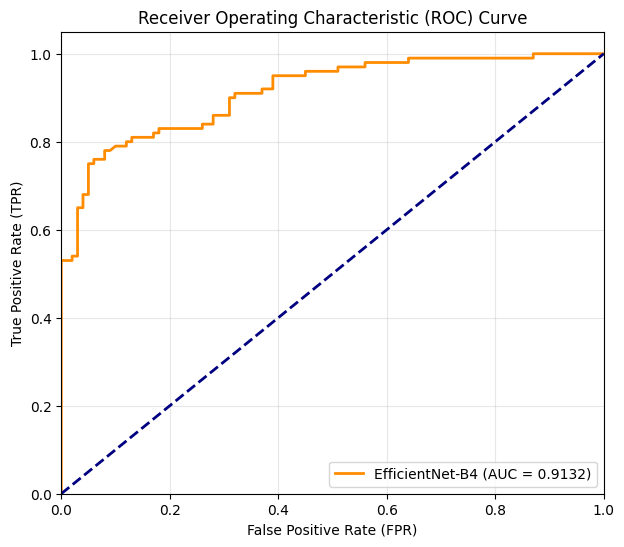

In [37]:
import os
import cv2
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, roc_auc_score, roc_curve, confusion_matrix
)

# ------------------------------------
# 1. Reproducibility & Device Setup
# ------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using Device:", DEVICE)

# OpenCV built-in face detector (No pip install required)
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

# ------------------------------------
# 2. Discover Videos Across Input Datasets
# ------------------------------------
VIDEO_EXTENSIONS = ('.mp4', '.avi', '.mov', '.mkv')
real_videos = []
fake_videos = []

for root, _, files in os.walk('/kaggle/input'):
    for file in files:
        if file.lower().endswith(VIDEO_EXTENSIONS):
            path = os.path.join(root, file)
            folder = root.lower()
            
            if 'celeb-real' in folder or 'youtube-real' in folder or 'original_sequences' in folder:
                real_videos.append(path)
            elif 'celeb-synthesis' in folder or 'manipulated_sequences' in folder or 'ff-c23' in folder:
                fake_videos.append(path)

print(f"Discovered -> Real Videos: {len(real_videos)}, Fake Videos: {len(fake_videos)}")

# ------------------------------------
# 3. Extract & Crop 1,000 Face Frames (500 Real / 500 Fake)
# ------------------------------------
TOTAL_FRAMES_TARGET = 1000
target_per_class = TOTAL_FRAMES_TARGET // 2

def extract_cropped_faces(video_list, target_count, label):
    extracted = []
    if not video_list:
        return extracted
    
    random.shuffle(video_list)
    frames_per_vid = max(1, math.ceil(target_count / len(video_list)))
    
    for vid_path in tqdm(video_list, desc=f"Extracting Faces (Label {label})"):
        cap = cv2.VideoCapture(vid_path)
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        if total_frames <= 0:
            cap.release()
            continue
            
        needed = min(frames_per_vid, target_count - len(extracted))
        indices = np.linspace(0, total_frames - 1, num=min(needed, total_frames), dtype=int)
        
        for idx in indices:
            cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
            ret, frame = cap.read()
            if ret:
                frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
                
                # Detect face region using Haar Cascade
                faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(60, 60))
                
                if len(faces) > 0:
                    x, y, w, h = faces[0]
                    # Add 10% padding around face box
                    pad_w, pad_h = int(w * 0.1), int(h * 0.1)
                    y1 = max(0, y - pad_h)
                    y2 = min(frame_rgb.shape[0], y + h + pad_h)
                    x1 = max(0, x - pad_w)
                    x2 = min(frame_rgb.shape[1], x + w + pad_w)
                    cropped_face = frame_rgb[y1:y2, x1:x2]
                    extracted.append((cv2.resize(cropped_face, (224, 224)), label))
                else:
                    # Fallback to full frame resize if face isn't bounding-detected
                    extracted.append((cv2.resize(frame_rgb, (224, 224)), label))
                    
                if len(extracted) >= target_count:
                    break
        cap.release()
        if len(extracted) >= target_count:
            break
            
    return extracted

real_data = extract_cropped_faces(real_videos, target_per_class, label=0)
fake_data = extract_cropped_faces(fake_videos, target_per_class, label=1)

dataset_raw = real_data + fake_data
print(f"Extracted Total Face Frames: {len(dataset_raw)} (Real: {len(real_data)}, Fake: {len(fake_data)})")

# ------------------------------------
# 4. PyTorch Dataset & Transforms
# ------------------------------------
class DeepfakeDataset(Dataset):
    def __init__(self, data_list, transform=None):
        self.data_list = data_list
        self.transform = transform

    def __len__(self):
        return len(self.data_list)

    def __getitem__(self, idx):
        img_np, label = self.data_list[idx]
        img = Image.fromarray(img_np)
        if self.transform:
            img = self.transform(img)
        return img, torch.tensor(label, dtype=torch.float32)

IMG_SIZE = 224
BATCH_SIZE = 16

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

labels = [item[1] for item in dataset_raw]
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, val_idx = next(sss.split(dataset_raw, labels))

train_data = [dataset_raw[i] for i in train_idx]
val_data = [dataset_raw[i] for i in val_idx]

train_dataset = DeepfakeDataset(train_data, transform=train_transform)
val_dataset = DeepfakeDataset(val_data, transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Training on {len(train_dataset)} frames, Validating on {len(val_dataset)} frames.")

# ------------------------------------
# 5. EfficientNet-B4 Architecture & Layer Unfreezing
# ------------------------------------
model = models.efficientnet_b4(weights=models.EfficientNet_B4_Weights.DEFAULT)

# Unfreeze top feature layers to allow deepfake artifact learning
for param in model.features[:-4].parameters():
    param.requires_grad = False

in_features = model.classifier[1].in_features
model.classifier = nn.Sequential(
    nn.Dropout(p=0.4),
    nn.Linear(in_features, 256),
    nn.SiLU(),
    nn.Dropout(p=0.3),
    nn.Linear(256, 1)
)
model = model.to(DEVICE)

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=2e-4, weight_decay=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=8)

# ------------------------------------
# 6. Training Loop (8 Epochs)
# ------------------------------------
EPOCHS = 8

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [Train]"):
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        
        optimizer.zero_grad()
        outputs = model(images).squeeze(1)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        
    scheduler.step()
    epoch_loss = running_loss / len(train_dataset)
    print(f"Epoch [{epoch+1}/{EPOCHS}] Training Loss: {epoch_loss:.4f}")

# ------------------------------------
# 7. Evaluation Metrics & ROC Curve
# ------------------------------------
model.eval()
all_targets = []
all_probs = []

with torch.no_grad():
    for images, labels in tqdm(val_loader, desc="Evaluating"):
        images = images.to(DEVICE)
        outputs = model(images).squeeze(1)
        probs = torch.sigmoid(outputs).cpu().numpy()
        
        all_probs.extend(probs)
        all_targets.extend(labels.numpy())

all_targets = np.array(all_targets)
all_probs = np.array(all_probs)
preds = (all_probs >= 0.5).astype(int)

# Calculate Metrics
acc = accuracy_score(all_targets, preds)
prec = precision_score(all_targets, preds, zero_division=0)
rec = recall_score(all_targets, preds, zero_division=0)
f1 = f1_score(all_targets, preds, zero_division=0)
auc = roc_auc_score(all_targets, all_probs)
cm = confusion_matrix(all_targets, preds)

print("\n" + "="*35)
print("       EVALUATION METRICS       ")
print("="*35)
print(f"Accuracy:  {acc * 100:.2f}%")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"ROC-AUC:   {auc:.4f}")
print("\nConfusion Matrix:")
print(cm)

# ------------------------------------
# 8. ROC Curve Plot
# ------------------------------------
fpr, tpr, _ = roc_curve(all_targets, all_probs)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'EfficientNet-B4 (AUC = {auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()